# Retail Sales and Inventory Planning
## 1. Data overview

This notebook checks the sales, calendar and price tables, then compares unit sales across stores, categories and dates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## 2. Loading the Dataset

In [2]:
calendar_path = "data/raw/calendar.csv"

calendar = pd.read_csv(calendar_path)

calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [3]:
calendar["date"] = pd.to_datetime(calendar["date"])

print(f"Calendar period: {calendar['date'].min().date()} — {calendar['date'].max().date()}")
print(f"Number of days: {calendar.shape[0]}")
print(f"Number of columns: {calendar.shape[1]}")

calendar.info()

Calendar period: 2011-01-29 — 2016-06-19
Number of days: 1969
Number of columns: 14
<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1969 non-null   datetime64[us]
 1   wm_yr_wk      1969 non-null   int64         
 2   weekday       1969 non-null   str           
 3   wday          1969 non-null   int64         
 4   month         1969 non-null   int64         
 5   year          1969 non-null   int64         
 6   d             1969 non-null   str           
 7   event_name_1  162 non-null    str           
 8   event_type_1  162 non-null    str           
 9   event_name_2  5 non-null      str           
 10  event_type_2  5 non-null      str           
 11  snap_CA       1969 non-null   int64         
 12  snap_TX       1969 non-null   int64         
 13  snap_WI       1969 non-null   int64         
dtypes: datetime64[u

### Events in the calendar

The calendar lists events and SNAP indicators. Below, I compare days with and without a recorded event. This comparison does not separate event effects from weekday or seasonal differences.

In [4]:
events = calendar[
    calendar["event_name_1"].notna() |
    calendar["event_name_2"].notna()
][
    ["date", "event_name_1", "event_type_1", "event_name_2", "event_type_2"]
]

events.head(10)

,date,event_name_1,event_type_1,event_name_2,event_type_2
8,2011-02-06,SuperBowl,Sporting,NaN,NaN
16,2011-02-14,ValentinesDay,Cultural,NaN,NaN
23,2011-02-21,PresidentsDay,National,NaN,NaN
39,2011-03-09,LentStart,Religious,NaN,NaN
46,2011-03-16,LentWeek2,Religious,NaN,NaN
47,2011-03-17,StPatricksDay,Cultural,NaN,NaN
50,2011-03-20,Purim End,Religious,NaN,NaN
85,2011-04-24,OrthodoxEaster,Religious,Easter,Cultural
87,2011-04-26,Pesach End,Religious,NaN,NaN
96,2011-05-05,Cinco De Mayo,Cultural,NaN,NaN


### Sales table

Each row is one product in one store. The `d_` columns contain daily unit sales.

In [5]:
sales_path = "data/raw/sales_train_validation.csv"

sales_sample = pd.read_csv(sales_path, nrows=5)

sales_sample.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8,d_9,d_10,d_11,d_12,d_13,d_14,d_15,d_16,d_17,d_18,d_19,...,d_1889,d_1890,d_1891,d_1892,d_1893,d_1894,d_1895,d_1896,d_1897,d_1898,d_1899,d_1900,d_1901,d_1902,d_1903,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,4,2,3,0,1,2,0,0,0,1,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0,0,0,0,1,2,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,3,1,2,1,3,1,0,2,5,4,2,0,3,0,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,4,0,1,4,0,1,0,1,0,1,1,2,0,1,1,2,1,1,0,1,1,2,2,2,4


In [6]:
sales_sample.columns.tolist()

['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9', 'd_10', 'd_11', 'd_12', 'd_13', 'd_14', 'd_15', 'd_16', 'd_17', 'd_18', 'd_19', 'd_20', 'd_21', 'd_22', 'd_23', 'd_24', 'd_25', 'd_26', 'd_27', 'd_28', 'd_29', 'd_30', 'd_31', 'd_32', 'd_33', 'd_34', 'd_35', 'd_36', 'd_37', 'd_38', 'd_39', 'd_40', 'd_41', 'd_42', 'd_43', 'd_44', 'd_45', 'd_46', 'd_47', 'd_48', 'd_49', 'd_50', 'd_51', 'd_52', 'd_53', 'd_54', 'd_55', 'd_56', 'd_57', 'd_58', 'd_59', 'd_60', 'd_61', 'd_62', 'd_63', 'd_64', 'd_65', 'd_66', 'd_67', 'd_68', 'd_69', 'd_70', 'd_71', 'd_72', 'd_73', 'd_74', 'd_75', 'd_76', 'd_77', 'd_78', 'd_79', 'd_80', 'd_81', 'd_82', 'd_83', 'd_84', 'd_85', 'd_86', 'd_87', 'd_88', 'd_89', 'd_90', 'd_91', 'd_92', 'd_93', 'd_94', 'd_95', 'd_96', 'd_97', 'd_98', 'd_99', 'd_100', 'd_101', 'd_102', 'd_103', 'd_104', 'd_105', 'd_106', 'd_107', 'd_108', 'd_109', 'd_110', 'd_111', 'd_112', 'd_113', 'd_114', 'd_115', 'd_116', '

In [7]:
sales_info = pd.read_csv(sales_path, nrows=0)

print(f"Number of columns: {len(sales_info.columns)}")
print(f"Number of daily sales columns: {len(sales_info.columns) - 6}")

Number of columns: 1919
Number of daily sales columns: 1913


In [8]:
sales = pd.read_csv(sales_path)

print(f"Rows: {sales.shape[0]:,}")
print(f"Columns: {sales.shape[1]:,}")

Rows: 30,490
Columns: 1,919


In [9]:
print("Products:", sales["item_id"].nunique())
print("Stores:", sales["store_id"].nunique())
print("Categories:", sales["cat_id"].nunique())

sales[["item_id", "dept_id", "cat_id", "store_id", "state_id"]].head()

Products: 3049
Stores: 10
Categories: 3


,item_id,dept_id,cat_id,store_id,state_id
0,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA
1,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA
2,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA
3,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA
4,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA


### Table structure

The validation file has 30,490 product-store rows, 3,049 products, 10 stores and 1,913 sales days. For the daily totals below, I sum the day columns directly; reshaping the full table is unnecessary.

## 3. Sales by category

Compare categories using total units sold over the observed period.

In [10]:
day_columns = [col for col in sales.columns if col.startswith("d_")]

category_sales = (
    sales.groupby("cat_id")[day_columns]
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
    .rename("total_units_sold")
    .reset_index()
)

category_sales

,cat_id,total_units_sold
0,FOODS,45089939
1,HOUSEHOLD,14480670
2,HOBBIES,6124800


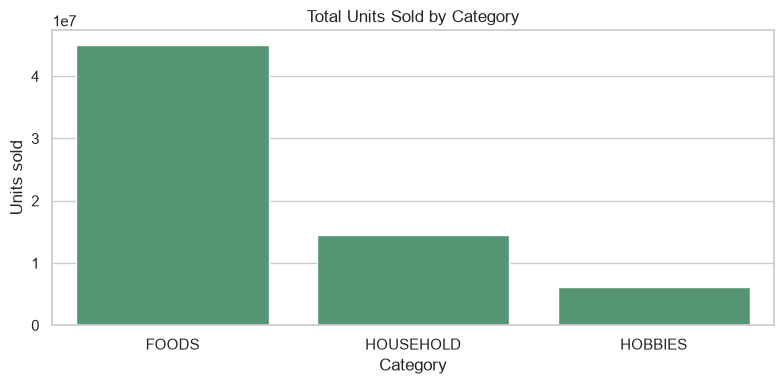

In [11]:
plt.figure(figsize=(8, 4))
sns.barplot(data=category_sales, x="cat_id", y="total_units_sold", color="#4C9F70")
plt.title("Total Units Sold by Category")
plt.xlabel("Category")
plt.ylabel("Units sold")
plt.tight_layout()
plt.show()

FOODS has the largest unit volume. This measures units sold, not revenue or profit; category size and product mix also affect the total.

In [12]:
store_sales = (
    sales.groupby(["state_id", "store_id"])[day_columns]
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
    .rename("total_units_sold")
    .reset_index()
)

store_sales

,state_id,store_id,total_units_sold
0,CA,CA_3,11188180
1,CA,CA_1,7698216
2,TX,TX_2,7214384
3,WI,WI_2,6544012
4,WI,WI_3,6427782
5,TX,TX_3,6089330
6,CA,CA_2,5685475
7,TX,TX_1,5595292
8,WI,WI_1,5149062
9,CA,CA_4,4103676


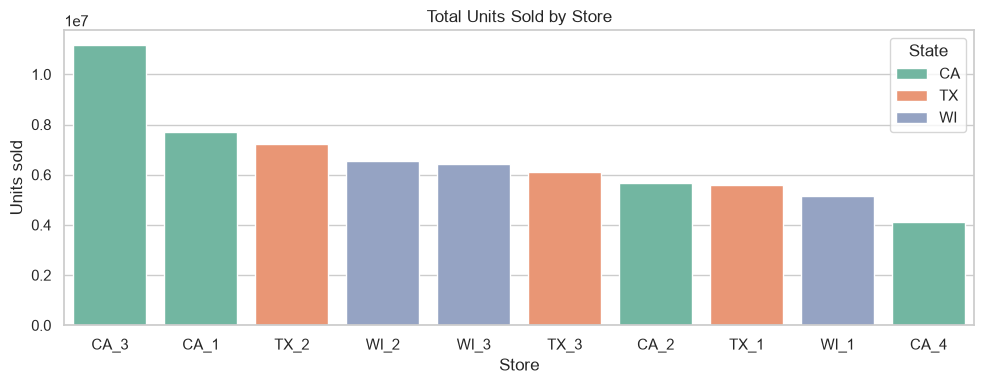

In [13]:
plt.figure(figsize=(10, 4))
sns.barplot(data=store_sales, x="store_id", y="total_units_sold", hue="state_id", dodge=False, palette="Set2")
plt.title("Total Units Sold by Store")
plt.xlabel("Store")
plt.ylabel("Units sold")
plt.legend(title="State")
plt.tight_layout()
plt.show()

## 4. Sales by store

CA_3 sold about 11.2 million units and CA_4 about 4.1 million. These totals show differences in sales volume, but do not explain them or establish the right stock policy for each store.

In [14]:

daily_sales = sales[day_columns].sum(axis=0).reset_index()
daily_sales.columns = ['d', 'units_sold']
daily_sales = daily_sales.merge(calendar[['d', 'date', 'weekday', 'month', 'year']], on='d', how='left')
daily_sales.head()

,d,units_sold,date,weekday,month,year
0,d_1,32631,2011-01-29,Saturday,1,2011
1,d_2,31749,2011-01-30,Sunday,1,2011
2,d_3,23783,2011-01-31,Monday,1,2011
3,d_4,25412,2011-02-01,Tuesday,2,2011
4,d_5,19146,2011-02-02,Wednesday,2,2011


## 5. Daily sales

The chart combines all products and stores. Individual items may follow different patterns.

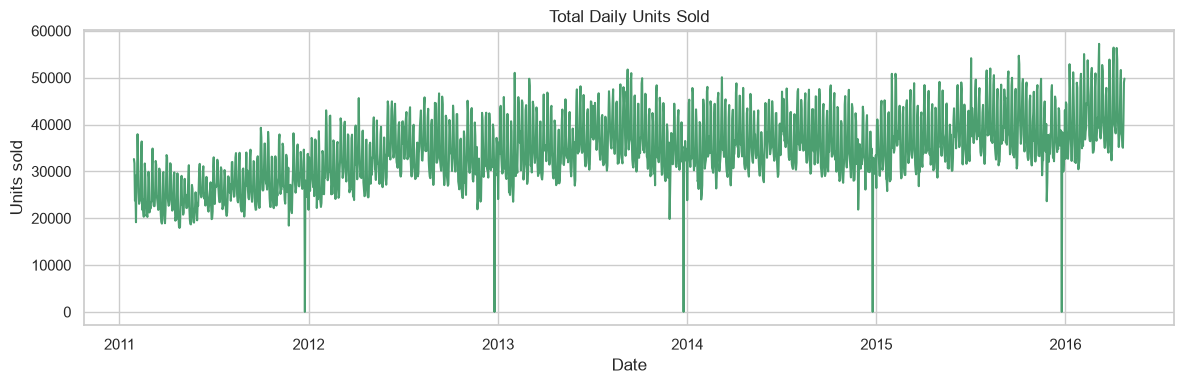

In [15]:
plt.figure(figsize=(12, 4))
sns.lineplot(data=daily_sales, x='date', y='units_sold', color='#4C9F70')
plt.title('Total Daily Units Sold')
plt.xlabel('Date')
plt.ylabel('Units sold')
plt.tight_layout()
plt.show()

The daily totals contain repeated peaks and dips. The weekday comparison below helps describe part of this variation.

In [16]:
weekday_sales = daily_sales.groupby('weekday', sort=False)['units_sold'].agg(['mean', 'median']).reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
weekday_sales

,mean,median
weekday,,
Monday,32852.967033,33444.0
Tuesday,30368.780220,30710.0
Wednesday,30010.021978,30911.0
Thursday,30205.007326,30658.0
Friday,34225.985348,34775.0
Saturday,41546.894161,42437.0
Sunday,41130.021898,42586.0


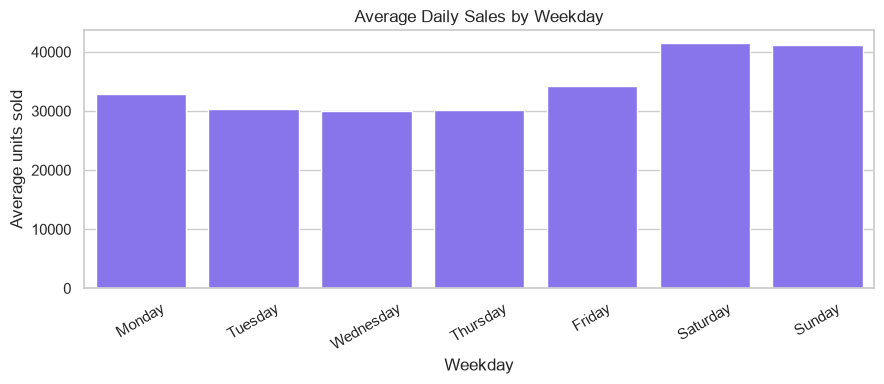

In [17]:

plt.figure(figsize=(9, 4))
sns.barplot(data=weekday_sales.reset_index(), x='weekday', y='mean', color='#7B61FF')
plt.title('Average Daily Sales by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Average units sold')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Weekend sales are higher in the aggregate. Before using this pattern for an item, check its sales in the store being replenished.

In [18]:

monthly_sales = daily_sales.groupby(['year', 'month'], as_index=False)['units_sold'].mean()
monthly_sales['month_name'] = pd.to_datetime(monthly_sales['month'], format='%m').dt.strftime('%b')
monthly_sales.head()

,year,month,units_sold,month_name
0,2011,1,29387.666667,Jan
1,2011,2,25941.964286,Feb
2,2011,3,24631.193548,Mar
3,2011,4,24590.433333,Apr
4,2011,5,23211.677419,May


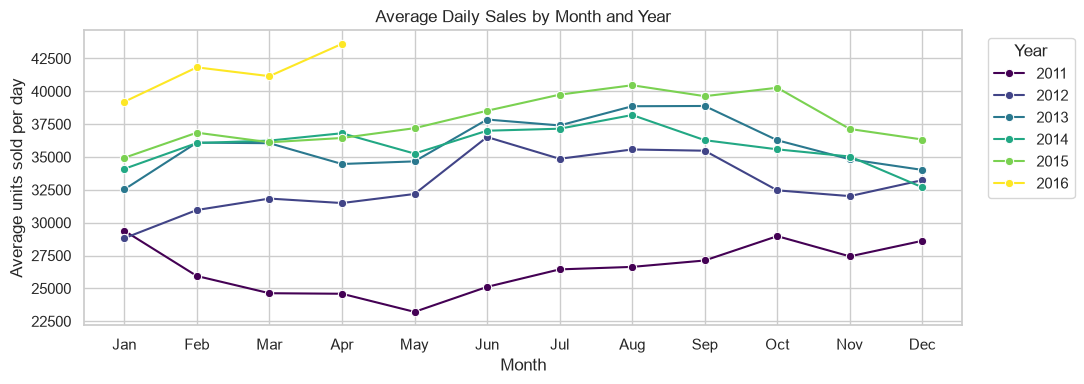

In [19]:

plt.figure(figsize=(11, 4))
sns.lineplot(data=monthly_sales, x='month_name', y='units_sold', hue='year', marker='o', palette='viridis')
plt.title('Average Daily Sales by Month and Year')
plt.xlabel('Month')
plt.ylabel('Average units sold per day')
plt.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Monthly sales

The chart uses average daily sales for each observed month, so month length does not drive the comparison. Partial months and changes between years still limit what it says about seasonality.

In [20]:

daily_sales_events = daily_sales.merge(calendar[['d', 'event_name_1', 'event_name_2']], on='d', how='left')
daily_sales_events['has_event'] = daily_sales_events['event_name_1'].notna() | daily_sales_events['event_name_2'].notna()
event_comparison = daily_sales_events.groupby('has_event')['units_sold'].agg(['mean', 'median', 'count'])
event_comparison = event_comparison.rename(index={False: 'No recorded event', True: 'Event day'})
event_comparison

,mean,median,count
has_event,,,
No recorded event,34489.207504,33714.0,1759
Event day,32655.149351,33779.5,154


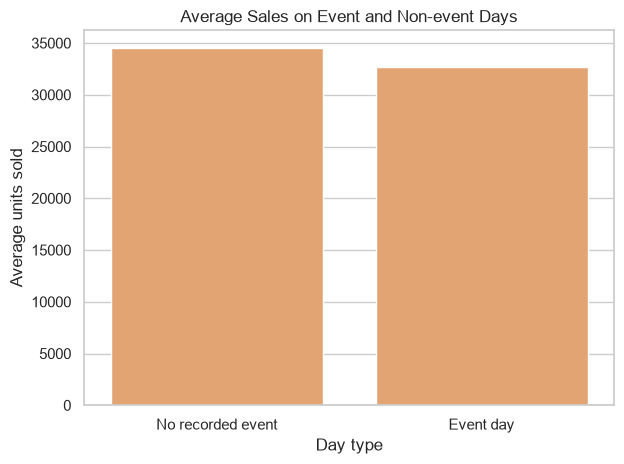

In [21]:

event_plot = event_comparison.rename_axis('day_type').reset_index()
sns.barplot(data=event_plot, x='day_type', y='mean', color='#F4A261')
plt.title('Average Sales on Event and Non-event Days')
plt.xlabel('Day type')
plt.ylabel('Average units sold')
plt.tight_layout()
plt.show()

## 7. Event days

The comparison covers sales dates only. Event days have lower average sales in this sample. This does not mean events reduce demand: the groups also differ in dates, weekdays and event types.

In [22]:

prices_path = "data/raw/sell_prices.csv"
prices = pd.read_csv(prices_path)
print(f"Rows: {prices.shape[0]:,}")
print(f"Columns: {prices.shape[1]:,}")
prices.head()

Rows: 6,841,121
Columns: 4


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


## 8. Weekly prices

Prices are recorded by item, store and week. This notebook only inspects the table; it does not estimate the effect of price changes.

In [23]:

product_sales = sales.groupby(['item_id', 'cat_id'])[day_columns].sum().sum(axis=1).rename('total_units_sold').reset_index()
product_sales = product_sales.sort_values('total_units_sold', ascending=False)
product_sales.head(10)

,item_id,cat_id,total_units_sold
702,FOODS_3_090,FOODS,1002529
1198,FOODS_3_586,FOODS,920242
864,FOODS_3_252,FOODS,565299
1167,FOODS_3_555,FOODS,491287
1325,FOODS_3_714,FOODS,396172
1199,FOODS_3_587,FOODS,396119
1306,FOODS_3_694,FOODS,390001
838,FOODS_3_226,FOODS,363082
814,FOODS_3_202,FOODS,295689
1334,FOODS_3_723,FOODS,284333


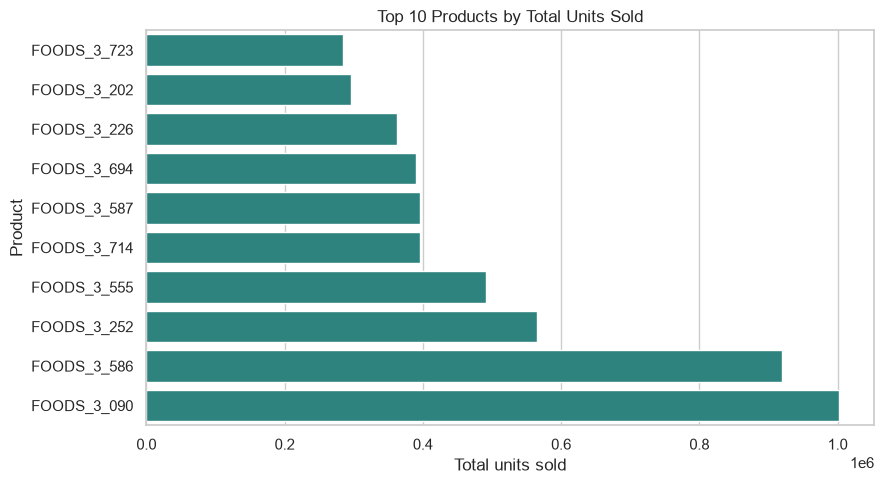

In [24]:

top_products = product_sales.head(10).sort_values('total_units_sold')
plt.figure(figsize=(9, 5))
sns.barplot(data=top_products, x='total_units_sold', y='item_id', hue='cat_id', dodge=False, legend=False, palette='viridis')
plt.title('Top 10 Products by Total Units Sold')
plt.xlabel('Total units sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

The ten highest-volume products belong to FOODS. Their rank is based on total sales across stores and the full period, so it may differ from a recent ranking for one store.

In [25]:

abc = product_sales.copy()
abc['share'] = abc['total_units_sold'] / abc['total_units_sold'].sum()
abc['cumulative_share'] = abc['share'].cumsum()
abc['abc_class'] = pd.cut(abc['cumulative_share'], bins=[0, 0.80, 0.95, 1.0], labels=['A', 'B', 'C'], include_lowest=True)
abc_summary = abc.groupby('abc_class', observed=False).agg(products=('item_id', 'count'), units=('total_units_sold', 'sum'), share=('share', 'sum'))
abc_summary['share'] = abc_summary['share'] * 100
abc_summary

,products,units,share
abc_class,,,
A,1033,52544890,79.982591
B,990,9860688,15.009706
C,1025,3289263,5.006838


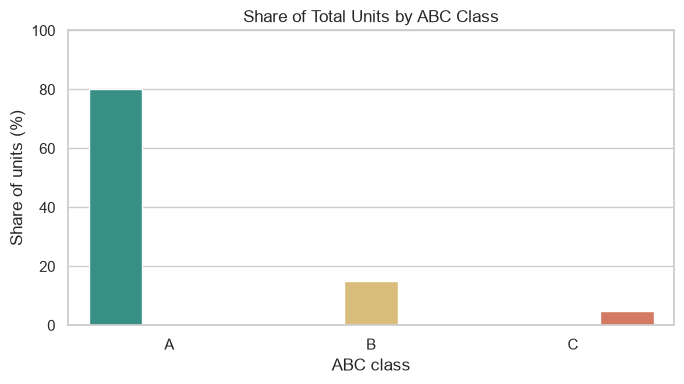

In [26]:

abc_plot = abc_summary.reset_index()
plt.figure(figsize=(7, 4))
sns.barplot(data=abc_plot, x='abc_class', y='share', hue='abc_class', palette=['#2A9D8F', '#E9C46A', '#E76F51'], legend=False)
plt.title('Share of Total Units by ABC Class')
plt.xlabel('ABC class')
plt.ylabel('Share of units (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 9. ABC groups

Products are sorted by units sold. Groups use cumulative shares of 80%, 95% and 100%. A product that crosses a boundary goes into the next group, so the resulting shares are approximate. This is a unit-volume ranking, not a profitability ranking.

## 10. What to check next

- Compare recent sales by product and store before setting stock targets.
- Review availability for A-items, alongside margins, shelf life and supplier lead times.
- Check whether the weekend pattern holds for the items being ordered.
- Study individual events separately before adjusting orders for them.

## 11. Limits

These tables describe recorded sales. Without stock availability, they cannot measure lost sales or total customer demand. The following notebooks look more closely at timing, product groups and a sample replenishment calculation.